<a href="https://colab.research.google.com/github/tanvimore2217/ML-Practical-10/blob/main/ML_ex_4_.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

In [ ]:
# Save your data as: electric_cars.csv
df = pd.read_csv("/content/cars.csv")

# Display first few rows
print("First 5 rows:")
print(df.head())

First 5 rows:
   YEAR        Make           Model        Size  (kW) Unnamed: 5 TYPE  \
0  2012  MITSUBISHI          i-MiEV  SUBCOMPACT    49         A1    B   
1  2012      NISSAN            LEAF    MID-SIZE    80         A1    B   
2  2013        FORD  FOCUS ELECTRIC     COMPACT   107         A1    B   
3  2013  MITSUBISHI          i-MiEV  SUBCOMPACT    49         A1    B   
4  2013      NISSAN            LEAF    MID-SIZE    80         A1    B   

   CITY (kWh/100 km)  HWY (kWh/100 km)  COMB (kWh/100 km)  CITY (Le/100 km)  \
0               16.9              21.4               18.7               1.9   
1               19.3              23.0               21.1               2.2   
2               19.0              21.1               20.0               2.1   
3               16.9              21.4               18.7               1.9   
4               19.3              23.0               21.1               2.2   

   HWY (Le/100 km)  COMB (Le/100 km)  (g/km)  RATING  (km)  TIME (h)  
0

In [ ]:
# Independent variable (X): Combined energy consumption
# Dependent variable (Y): Driving range

X = df[["COMB (kWh/100 km)"]]
y = df["(km)"]

# Remove missing values
data = pd.concat([X, y], axis=1).dropna()

X = data[["COMB (kWh/100 km)"]]
y = data["(km)"]

In [ ]:

model = LinearRegression()
model.fit(X, y)

# Predictions
y_pred = model.predict(X)


In [ ]:

slope = model.coef_[0]
intercept = model.intercept_

print("\nLinear Regression Equation:")
print(f"Range = {slope:.2f} × COMB Consumption + {intercept:.2f}")

print(f"\nSlope     : {slope:.2f}")
print(f"Intercept : {intercept:.2f}")


Linear Regression Equation:
Range = 57.72 × COMB Consumption + -946.41

Slope     : 57.72
Intercept : -946.41


In [ ]:
r2 = r2_score(y, y_pred)
mse = mean_squared_error(y, y_pred)

print(f"\nR² Score  : {r2:.4f}")
print(f"MSE       : {mse:.2f}")
print(f"RMSE      : {mse ** 0.5:.2f}")


R² Score  : 0.6526
MSE       : 6817.94
RMSE      : 82.57


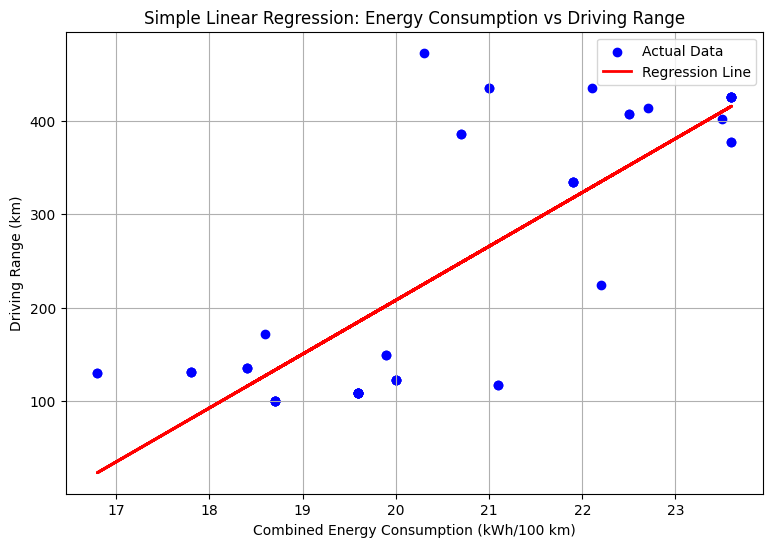

In [ ]:
plt.figure(figsize=(9, 6))

plt.scatter(
    X,
    y,
    color="blue",
    label="Actual Data"
)

plt.plot(
    X,
    y_pred,
    color="red",
    linewidth=2,
    label="Regression Line"
)

plt.xlabel("Combined Energy Consumption (kWh/100 km)")
plt.ylabel("Driving Range (km)")
plt.title("Simple Linear Regression: Energy Consumption vs Driving Range")
plt.legend()
plt.grid(True)

plt.show()

In [ ]:
new_consumption = [[20]]

predicted_range = model.predict(new_consumption)

print(
    f"\nPredicted range for a vehicle consuming "
    f"20 kWh/100 km: {predicted_range[0]:.2f} km"
)


Predicted range for a vehicle consuming 20 kWh/100 km: 207.92 km


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(
